# 3. Analysis 1, the quadrant

I scored market and conditions from 0 to 100, with a higher score meaning a stronger market or a stronger condition. The market score averages the shed size, the Toronto commute share, and the share of dwellings built from 2016 to 2021. The conditions score averages rail service, local connections, walk access, parking headroom, and fare. Parking is omitted, and the weights are renormalized, where there is no commuter lot of at least 50 spaces or the station is destination-leaning.

I split at the median. Priority means the market is at or above the median and the conditions are below it. This step only decides where to look. It does not name a cause.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
from scorecard.pipeline import load
table, recs, meta = load()

print("market median", round(meta["market_median"], 1), "conditions median", round(meta["conditions_median"], 1))
print(table[table.in_score].quadrant.value_counts().to_string())
print("rank correlation across weight schemes")
for k, v in meta["weight_spearman"].items():
    print(f"  {k}: {v:.3f}")
print("priority under every weight:", ", ".join(meta["priority_stable"]))

market median 50.7 conditions median 48.1
quadrant
market and conditions              21
market and conditions both thin    21
conditions ahead of market         14
priority                           14
rank correlation across weight schemes
  equal_vs_access_heavy: 0.970
  equal_vs_service_heavy: 0.974
  access_heavy_vs_service_heavy: 0.919
priority under every weight: BM, ET, GO, LA, MK, ML, MR, OL, OR, OS, RI, UI


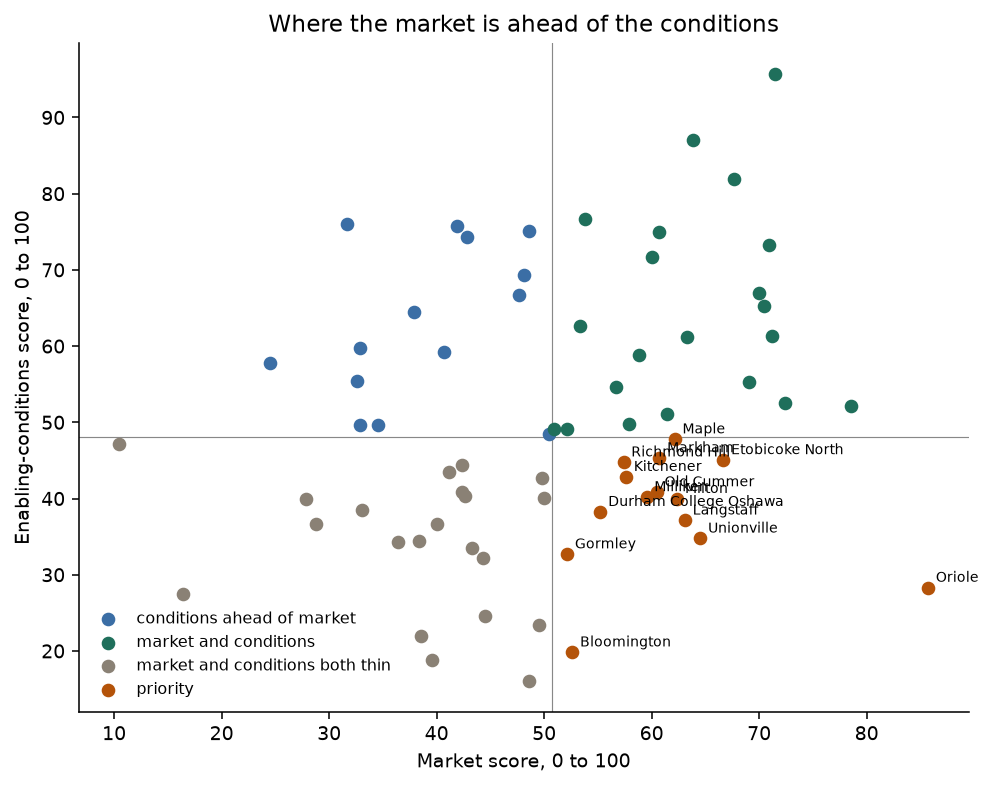

In [2]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "reports" / "figures" / "quadrant.png")))